# Overnight overshoot / reversal forecast (close auction → next open)

**Sister study to `../forecast/forecasting.ipynb`.** That notebook forecasts the *15:50 → 16:00*
close-auction move. Here we ask the follow-on question: **when the close-auction imbalance
*drives* the print away from fair value, does the price *overshoot* and then *revert overnight*?**

### The bet
The closing cross clears at a single price that absorbs a large, often one-sided, marketable
imbalance. If that imbalance is temporary liquidity demand (index rebalances, MOC flow, ETF
creation) rather than information, the auction print *overshoots* fair value and part of the move
should **reverse by the next opening auction**. So we want to **fade the close-auction move** —
short the names the imbalance pushed *up* into the close, long the ones it pushed *down* — and
unwind at the next open.

### Tradeable structure (auctions only)
We assume liquidity only in/around the two auctions, so the trade is fully auction-to-auction:

- **Entry:** the **closing auction** on day *t* (price = `close_auction_price`, `stat_type == 11`).
- **Exit:** the **next opening auction** on day *t+1* (price = `open_auction_price`, `stat_type == 1`),
  with a second variant exiting at the **open + first few minutes** mid (~09:33–09:35) to see whether
  the reversion completes at the open cross or bleeds into the first minutes.

Every feature is known by 16:00 on day *t*, so there is no look-ahead.

### Target
`overnight_return = (next_open_auction − close_auction_price) / close_auction_price`, then
**cross-sectionally demeaned per day** (`overnight_return_xm`) — the alpha is relative/market-neutral,
matching the optimizer's neutrality constraints. **Reversal ⇒ we expect a _negative_ loading on the
close overshoot** (and a stronger negative loading when the auction was large relative to ADV, i.e.
the imbalance was actually driving price).

### Collecting Data

Same preamble as `forecasting.ipynb` — imbalance / tbbo / statistics over the 2025-06-11 .. 2026-06-11 window on `top_100_universe.txt`. We additionally keep the **opening** auction (`stat_type == 1`) from `statistics`.

In [1]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
load_dotenv()
pl.enable_string_cache()

CACHE_DIR = Path.cwd().resolve().parents[0] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

print(f"CACHE_DIR: {CACHE_DIR}")

with open("../universe.txt", "r") as f:
    UNIVERSE = [line.strip() for line in f]
with open("../top_100_universe.txt", "r") as f:
    ACTIVE_SET = [line.strip() for line in f]
START = "2025-06-11"
END = "2026-06-11"
DATASET = "XNAS.ITCH"

# Close-auction imbalance print (reference imbalance ~10 min before the close)
df_imbalance = (
    adapter.scan_data(
        tickers=UNIVERSE, start_date=START, end_date=END, dataset=DATASET, schema="imbalance"
    )
    .select(["ts_event", "symbol", "side", "total_imbalance_qty", "paired_qty", "ref_price", "auct_interest_clr_price"])
    .with_columns(
        pl.col("ts_event").dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical),
    )
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(9, 30), pl.time(16, 0)),
            pl.col("symbol").is_in(ACTIVE_SET))
)

# Trades with the bbo (for pre-close mid, ADV, and the open + first-few-minutes mid)
df_trades = (
    adapter.scan_data(
        tickers=UNIVERSE, start_date=START, end_date=END, dataset=DATASET, schema="tbbo"
    )
    .select(["ts_event", "symbol", "price", "size", "ask_px_00", "bid_px_00"])
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(13, 30), pl.time(21, 0)),
            pl.col("symbol").is_in(ACTIVE_SET))
    .with_columns(pl.col("ts_event").dt.convert_time_zone("America/New_York"))
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(9, 30), pl.time(16, 0)))
    .with_columns(pl.col("symbol").cast(pl.Categorical))
)

# statistics: closing auction (stat_type == 11) AND opening auction (stat_type == 1)
df_stats = (
    adapter.scan_data(
        tickers=UNIVERSE, start_date=START, end_date=END, dataset=DATASET, schema="statistics"
    )
    .select(["ts_event", "stat_type", "symbol", "price", "quantity"])
    .with_columns(
        pl.col("ts_event").dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical),
    )
    .filter(pl.col("stat_type").is_in([1, 11]),
            pl.col("symbol").is_in(ACTIVE_SET))
)

CACHE_DIR: /Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/data/dbn_cache/generic
[GenericAdapter] scan_parquet: 015b0f098e17be916bbb238312a4d5d4.parquet
[GenericAdapter] scan_parquet: 6436dd54a7ced32262a3242e08d42d20.parquet
[GenericAdapter] scan_parquet: 83ab27f48711d5689292fe953cab702b.parquet


### Daily aggregates

One row per `(date, symbol)`: the close-auction imbalance print, the pre-auction mid (`entry_price`, the "fair value" the overshoot is measured from), the **close** and **open** auction prices, the open + first-few-minutes mid, a late-day drift feature, and a causal ADV.

In [2]:
# EWMA average daily dollar volume (causal: shifted so day t uses only info < t)
adv = (
    df_trades
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"])
    .agg((pl.col("size") * pl.col("price")).sum().alias("day_volume"))
    .sort(["date", "symbol"])
    .with_columns(
        pl.col("day_volume").ewm_mean(span=10, adjust=True).shift(1)
        .over("symbol", order_by="date").alias("ADV")
    )
    .drop("day_volume")
    .collect(engine="streaming")
)

# Official auction prices
close_auction = (
    df_stats.filter(pl.col("stat_type") == 11)
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .select("date", "symbol", pl.col("price").alias("close_auction_price"))
    .collect(engine="streaming")
)
open_auction = (
    df_stats.filter(pl.col("stat_type") == 1)
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .select("date", "symbol", pl.col("price").alias("open_auction_price"))
    .collect(engine="streaming")
)

# Pre-auction mid at ~15:50 — the fair-value reference the close overshoot is measured against
entry_mid = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"),
    )
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15, 49, 55), pl.time(15, 50, 0)))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(pl.col("mid").last().alias("entry_price"))
    .collect(engine="streaming")
)

# Open + first few minutes mid (~09:33-09:35) — the alternative "slightly after the open cross" exit
open_5min = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"),
    )
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(9, 33), pl.time(9, 35)))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(pl.col("mid").mean().alias("open_5min_mid"))
    .collect(engine="streaming")
)

# Late-day drift into the close (15:45 -> 15:50) — momentum context for the overshoot
recent_return = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"),
    )
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15, 55, 0), pl.time(15, 57, 45)))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(((pl.col("mid").last() - pl.col("mid").first()) / pl.col("mid").first()).alias("recent_return"))
    .collect(engine="streaming")
)

# The reference close-auction imbalance print (first message in the 15:50:00-15:50:05 window)
imb_print = (
    df_imbalance
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15, 50, 0), pl.time(15, 50, 5)))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(pl.col(["side", "total_imbalance_qty", "paired_qty", "ref_price"]).first())
    .collect(engine="streaming")
)

implied_return = (
    df_imbalance
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15, 55, 0), pl.time(15, 57, 45)))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg((pl.col("auct_interest_clr_price")/pl.col("ref_price") - 1).first().alias("implied_return"))
    .collect(engine="streaming")
)

In [3]:
# implied_return = (
#     df_imbalance
#     .filter(pl.col("ts_event").dt.time().is_between(pl.time(15, 55, 0), pl.time(15, 57, 45)))
#     .with_columns(pl.col("ts_event").dt.date().alias("date"))
#     .group_by(["date", "symbol"], maintain_order=True)
#     .agg((pl.col("auct_interest_clr_price")/pl.col("ref_price") - 1).first().alias("implied_return"))
#     .collect(engine="streaming")
# )
# implied_return

### Assemble target + features

The **overnight exit** is the *next trading day's* open, so we shift the open prices back by one
row **within each symbol** (`shift(-1) over symbol`). This naturally spans weekends/holidays; we
guard against long gaps (`gap_days <= 4`) so a stale row doesn't masquerade as an overnight hold.

Features (all known by 16:00 on day *t*), cross-sectionally demeaned per day where it matters:
- **`close_overshoot`** — the realized close-auction move `(close_auction − entry_mid) / entry_mid`.
  This *is* the overshoot; the reversal bet is a **negative** loading here.
- **`net_signed_imb`** / **`norm_rank_net_imb`** — signed imbalance / paired, and its per-day rank
  in [-1, 1]: the *direction* the imbalance pushed.
- **`auction_dollar_volume_ratio`** — paired auction $ / ADV: how much the auction **dominated**
  normal volume, i.e. a proxy for "the imbalance is driving price."
- **Interactions** — `overshoot × auction_ratio` (overshoot *when the auction was large*, the
  cleanest "imbalance-driven overshoot" term) and `overshoot × rank_imb`, `rank_imb × auction_ratio`.

In [7]:
feat = (
    imb_print
    .join(entry_mid,     on=["date", "symbol"])
    .join(close_auction, on=["date", "symbol"])
    .join(open_auction,  on=["date", "symbol"])
    .join(open_5min,     on=["date", "symbol"])
    .join(recent_return, on=["date", "symbol"])
    .join(adv,           on=["date", "symbol"])
    .join(implied_return, on=["date", "symbol"])
    .sort(["symbol", "date"])
    # --- overnight exit = NEXT trading day's open, shifted within symbol ---
    .with_columns(
        pl.col("open_auction_price").shift(-1).over("symbol", order_by="date").alias("next_open_auction"),
        pl.col("open_5min_mid").shift(-1).over("symbol", order_by="date").alias("next_open_5min"),
        pl.col("date").shift(-1).over("symbol", order_by="date").alias("next_date"),
    )
    .with_columns((pl.col("next_date") - pl.col("date")).dt.total_days().alias("gap_days"))
    # --- signed dollar imbalance ---
    .with_columns(
        (pl.col("total_imbalance_qty") * pl.col("ref_price")).alias("dollar_imbalance"),
        (pl.col("paired_qty") * pl.col("ref_price")).alias("paired_dollars"),
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .when(pl.col("side") == "N").then(0)
        ).alias("sign"),
    )
    .with_columns((pl.col("sign") * pl.col("dollar_imbalance")).alias("signed_dollar_imbalance"))
    .drop_nulls(subset=["next_open_auction", "next_open_5min", "ADV", "entry_price", "close_auction_price"])
    .filter(pl.col("gap_days") <= 4)  # drop stale/long-gap "overnights"
    # --- raw ratios, overshoot, and overnight target ---
    .with_columns(
        (pl.col("paired_dollars") / pl.col("ADV")).alias("auction_dollar_volume_ratio"),
        (
            pl.when(pl.col("paired_dollars") != 0)
            .then(pl.col("signed_dollar_imbalance") / pl.col("paired_dollars"))
            .otherwise(0)
        ).alias("net_signed_imb"),
        ((pl.col("close_auction_price") - pl.col("entry_price")) / pl.col("entry_price")).alias("close_overshoot"),
        ((pl.col("next_open_auction") - pl.col("close_auction_price")) / pl.col("close_auction_price")).alias("overnight_return"),
        ((pl.col("next_open_5min") - pl.col("close_auction_price")) / pl.col("close_auction_price")).alias("overnight_return_5min"),
    )
    # --- cross-sectional (per-day) demeaning + rank + interactions ---
    .with_columns(
        (pl.col("overnight_return") - pl.col("overnight_return").mean().over("date")).alias("overnight_return_xm"),
        (pl.col("overnight_return_5min") - pl.col("overnight_return_5min").mean().over("date")).alias("overnight_return_5min_xm"),
        (pl.col("close_overshoot") - pl.col("close_overshoot").mean().over("date")).alias("close_overshoot_xm"),
        (pl.col("recent_return") - pl.col("recent_return").mean().over("date")).alias("recent_return_xm"),
        (pl.col("implied_return").rank().over("date")).alias("implied_return_xm"),
        (pl.col("auction_dollar_volume_ratio") - pl.col("auction_dollar_volume_ratio").mean().over("date")).alias("auction_dollar_volume_ratio_xm"),
        (
            ((pl.col("net_signed_imb").rank().over("date") - pl.col("net_signed_imb").rank().min().over("date"))
             / (pl.col("net_signed_imb").rank().max().over("date") - pl.col("net_signed_imb").rank().min().over("date")))
            * 2 - 1
        ).alias("norm_rank_net_imb"),
    )
    .with_columns(
        (pl.col("close_overshoot_xm") * pl.col("auction_dollar_volume_ratio_xm")).alias("overshoot_x_auction"),
        (pl.col("close_overshoot_xm") * pl.col("norm_rank_net_imb")).alias("overshoot_x_rank"),
        (pl.col("norm_rank_net_imb") * pl.col("auction_dollar_volume_ratio_xm")).alias("rank_x_auction"),
        (pl.col("close_overshoot_xm") * pl.col("implied_return_xm")).alias("overshoot_x_implied")
    )
)

print(f"rows: {feat.height:,}   dates: {feat['date'].n_unique()}   symbols: {feat['symbol'].n_unique()}")
feat.select(["date", "symbol", "close_overshoot", "auction_dollar_volume_ratio",
             "norm_rank_net_imb", "overnight_return", "overnight_return_5min", "implied_return", "recent_return", "recent_return_xm", "overshoot_x_implied"]).head()

rows: 16,578   dates: 244   symbols: 95


date,symbol,close_overshoot,auction_dollar_volume_ratio,norm_rank_net_imb,overnight_return,overnight_return_5min,implied_return,recent_return,recent_return_xm,overshoot_x_implied
date,cat,f64,f64,f64,f64,f64,f64,f64,f64,f64
2025-06-12,"""AAPL""",0.003147,0.282215,-0.384615,0.001205,0.000229,0.016152,0.000981,0.000498,0.088654
2025-06-13,"""AAPL""",0.001683,0.347476,0.119048,0.003818,0.003084,0.0197,0.000153,0.00013,0.085332
2025-06-16,"""AAPL""",-0.000176,0.367281,-0.152941,-0.006753,-0.006379,0.015642,-0.000126,0.000294,-0.026886
2025-06-17,"""AAPL""",-0.000383,0.308293,0.211268,0.001278,-0.001579,0.002759,-0.000766,-0.000457,0.032195
2025-06-18,"""AAPL""",0.001401,0.3168,0.661017,0.009106,0.013113,0.03332,0.000916,0.000573,0.116082


## Exploratory — does the close overshoot revert overnight?

Quick, model-free checks before fitting anything: the cross-sectional rank IC of the raw overshoot against the overnight return, and a **decile** view — sort each day into deciles of `close_overshoot` and look at the mean subsequent overnight return. A downward-sloping relationship (top overshoot deciles → negative overnight return) is the reversal we're betting on.

In [8]:
from scipy.stats import spearmanr, pearsonr

# Daily cross-sectional rank IC of the raw overshoot vs the overnight return (both exits)
def daily_ic(df, xcol, ycol):
    ics = (
        df.group_by("date")
        .agg(pl.map_groups([xcol, ycol],
             lambda s: spearmanr(s[0], s[1]).statistic,
             return_dtype=pl.Float64, returns_scalar=True).alias("ic"))
        .drop_nulls()["ic"]
    )
    return ics.mean(), ics.std(), ics.mean() / ics.std()

for tgt in ["overnight_return_xm", "overnight_return_5min_xm"]:
    m, s, ir = daily_ic(feat, "recent_return_xm", tgt)
    print(f"overshoot -> {tgt:28s}  mean IC {m:+.4f}  std {s:.4f}  IR {ir:+.2f}")
for tgt in ["overnight_return_xm"]:
    m, s, ir = daily_ic(feat, "norm_rank_net_imb", tgt)
    print(f"rank_imb  -> {tgt:28s}  mean IC {m:+.4f}  std {s:.4f}  IR {ir:+.2f}")

# Decile view: per day, bucket by close_overshoot; average overnight return within each bucket
dec = (
    feat
    .with_columns((pl.col("close_overshoot").rank().over("date")
                   / pl.col("close_overshoot").count().over("date") * 10).ceil().clip(1, 10).alias("overshoot_decile"))
    .group_by("overshoot_decile")
    .agg(
        pl.col("overnight_return_xm").mean().alias("mean_overnight_xm"),
        (pl.col("overnight_return_xm").mean() / pl.col("overnight_return_xm").std()
         * pl.col("overnight_return_xm").count().sqrt()).alias("t_stat"),
        pl.len().alias("n"),
    )
    .sort("overshoot_decile")
)
dec

overshoot -> overnight_return_xm           mean IC -0.0132  std 0.1966  IR -0.07
overshoot -> overnight_return_5min_xm      mean IC -0.0078  std 0.1918  IR -0.04
rank_imb  -> overnight_return_xm           mean IC +0.0011  std 0.1589  IR +0.01


overshoot_decile,mean_overnight_xm,t_stat,n
f64,f64,f64,u64
1.0,0.000548,0.877936,1547
2.0,0.000727,1.463478,1669
3.0,-0.000327,-0.797832,1653
4.0,0.000064,0.138322,1654
5.0,-0.000921,-1.119406,1711
6.0,-0.000201,-0.426797,1620
7.0,-0.000279,-0.681309,1636
8.0,0.000254,0.583836,1671
9.0,-0.000639,-1.297063,1651


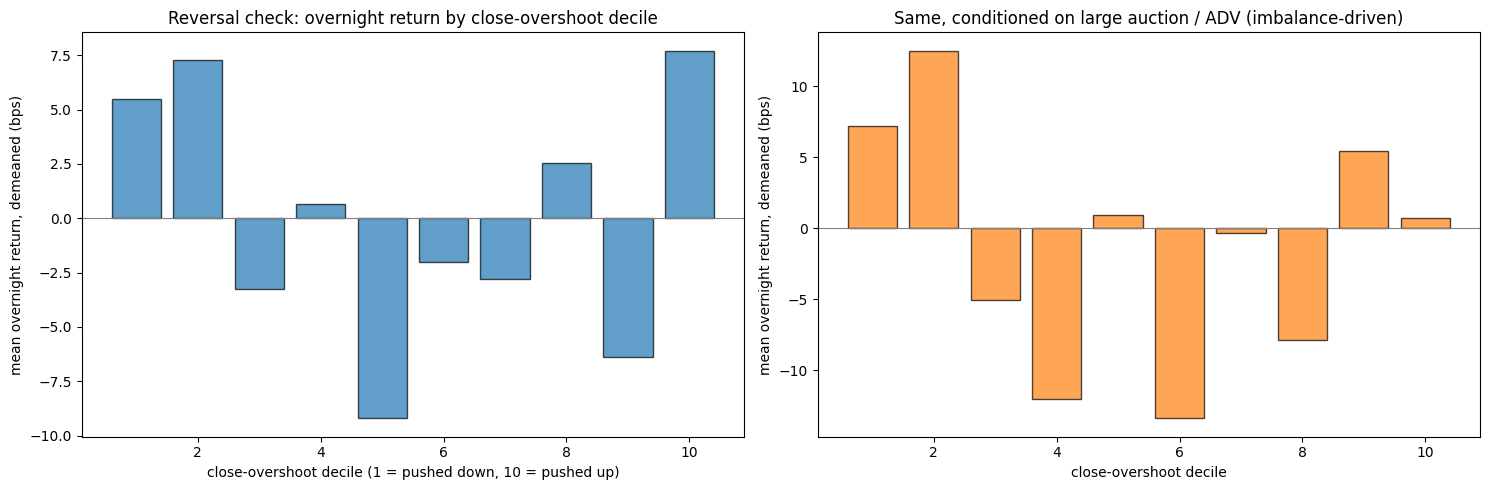

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

d = dec.to_pandas()
ax[0].bar(d["overshoot_decile"], d["mean_overnight_xm"] * 1e4, edgecolor="black", alpha=0.7)
ax[0].axhline(0, color="grey", lw=0.8)
ax[0].set_xlabel("close-overshoot decile (1 = pushed down, 10 = pushed up)")
ax[0].set_ylabel("mean overnight return, demeaned (bps)")
ax[0].set_title("Reversal check: overnight return by close-overshoot decile")

# Same, but only when the auction was LARGE relative to ADV (imbalance actually driving price)
big = feat.filter(pl.col("auction_dollar_volume_ratio") > pl.col("auction_dollar_volume_ratio").median())
dec_big = (
    big
    .with_columns((pl.col("close_overshoot").rank().over("date")
                   / pl.col("close_overshoot").count().over("date") * 10).ceil().clip(1, 10).alias("dec"))
    .group_by("dec").agg(pl.col("overnight_return_xm").mean().alias("m")).sort("dec").to_pandas()
)
ax[1].bar(dec_big["dec"], dec_big["m"] * 1e4, edgecolor="black", alpha=0.7, color="tab:orange")
ax[1].axhline(0, color="grey", lw=0.8)
ax[1].set_xlabel("close-overshoot decile")
ax[1].set_ylabel("mean overnight return, demeaned (bps)")
ax[1].set_title("Same, conditioned on large auction / ADV (imbalance-driven)")
fig.tight_layout()
plt.show()

In [10]:
dec_big

,dec,m
0,1.0,0.000716
1,2.0,0.001249
2,3.0,-0.000503
3,4.0,-0.001205
4,5.0,0.000093
5,6.0,-0.001339
6,7.0,-0.000037
7,8.0,-0.000785
8,9.0,0.000544
9,10.0,0.000068


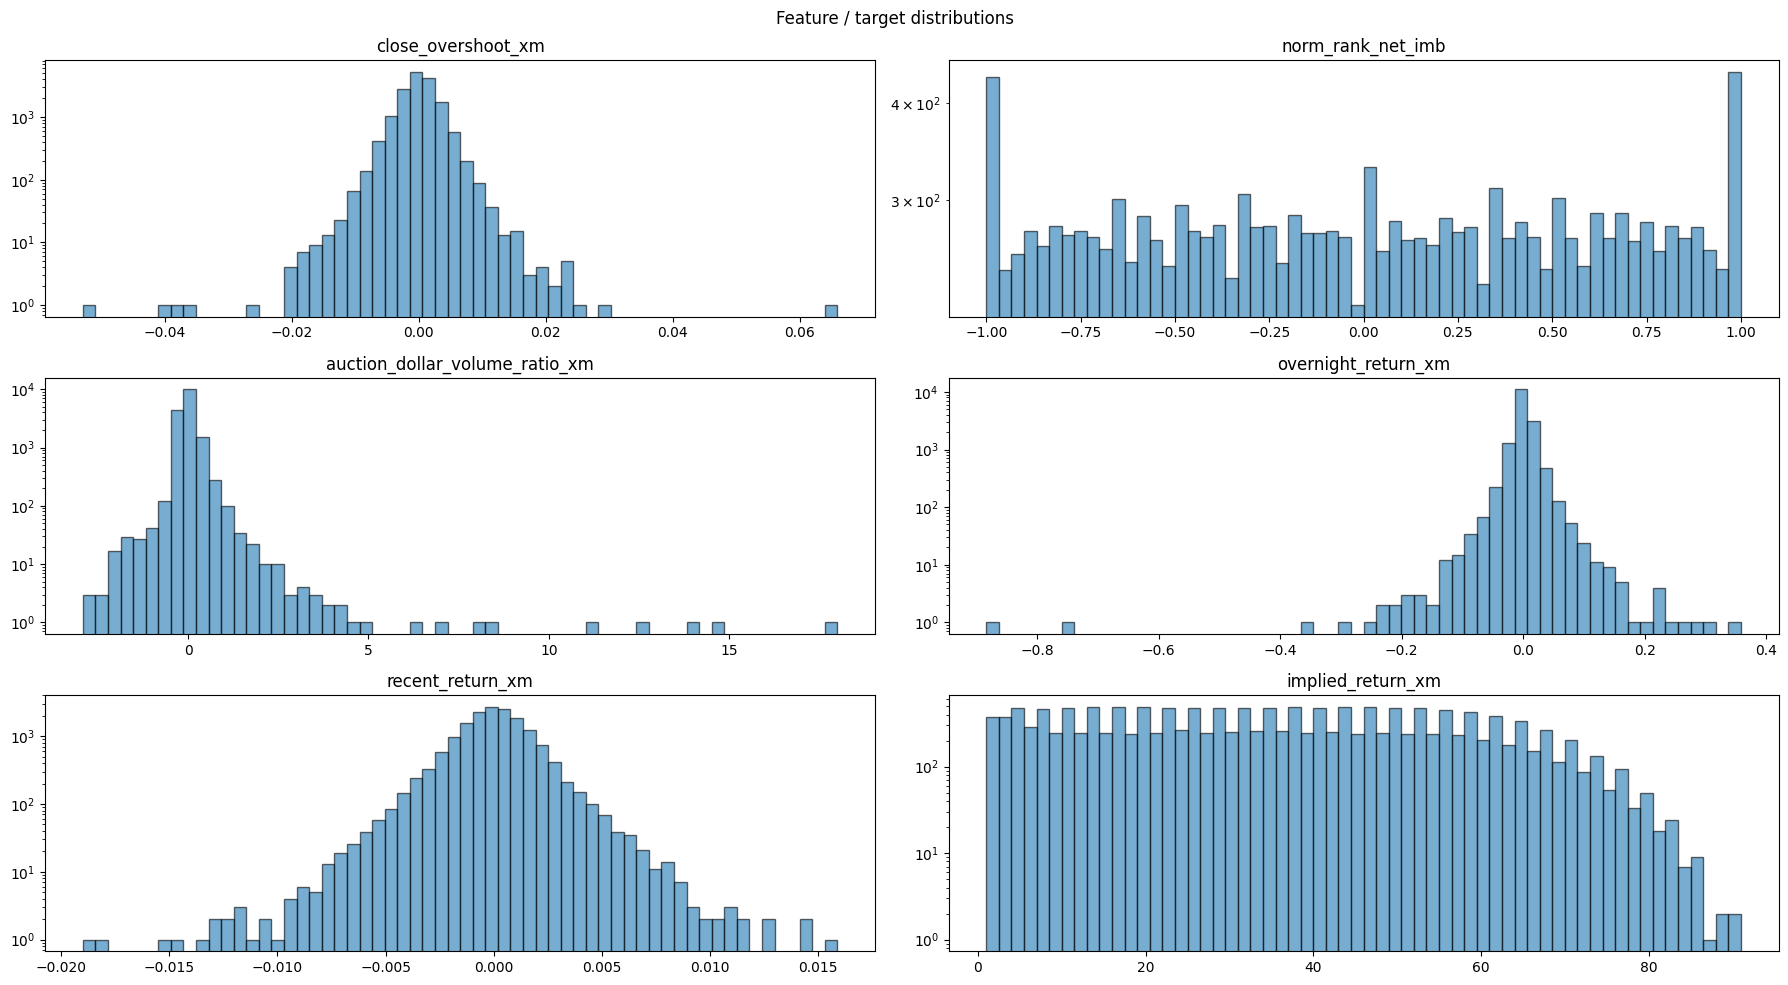

In [11]:
plot_features = [
    "close_overshoot_xm",
    "norm_rank_net_imb",
    "auction_dollar_volume_ratio_xm",
    "overnight_return_xm",
    "recent_return_xm",
    "implied_return_xm"
]
fig, axes = plt.subplots(3, 2, figsize=(18, 10))
for ax, feat_name in zip(axes.flat, plot_features):
    ax.hist(feat[feat_name].to_numpy(), bins=60, alpha=0.6, edgecolor="black")
    ax.set_yscale("log")
    ax.set_title(feat_name)
fig.suptitle("Feature / target distributions")
fig.tight_layout()
plt.show()

## Cross Validation

Same protocol as `forecasting.ipynb`: split on **unique dates** (a day's cross-section stays
whole — no leakage) with a rolling `TimeSeriesSplit`, and score each fold by mean **daily rank IC**
(Spearman) plus MSE / R². We compare feature sets built around the reversal thesis, using **Ridge**
(the close-forecast notebook's chosen linear model). Target is the overnight (close→open) demeaned return.

In [16]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error

dates = feat["date"].unique().sort().to_list()
feature_sets = [
    # just the overshoot
    ["close_overshoot_xm"],
    ["implied_return_xm"],
    ["close_overshoot_xm", "implied_return_xm"],
    # overshoot + how much the imbalance dominated (imbalance-driven overshoot)
    ["close_overshoot_xm", "auction_dollar_volume_ratio_xm", "overshoot_x_auction"],
    # overshoot + imbalance direction + interaction
    ["close_overshoot_xm", "norm_rank_net_imb", "overshoot_x_rank"],
    # the full reversal feature set
    ["close_overshoot_xm", "norm_rank_net_imb", "auction_dollar_volume_ratio_xm",
     "overshoot_x_auction", "overshoot_x_rank", "rank_x_auction", "recent_return_xm"],
]
target = ["overnight_return_5min_xm"]

tscv = TimeSeriesSplit(n_splits=20, max_train_size=120, test_size=5)  # rolling ~train window
scaler = StandardScaler()

for features in feature_sets:
    fold_ics, fold_r2 = [], []
    for train_d, test_d in tscv.split(dates):
        train_dates = [dates[j] for j in train_d]
        test_dates = [dates[j] for j in test_d]
        train = feat.filter(pl.col("date").is_in(train_dates),)
        test = feat.filter(pl.col("date").is_in(test_dates))

        X_tr = scaler.fit_transform(train[features].to_numpy())
        y_tr = train[target].to_numpy()
        X_te = scaler.transform(test[features].to_numpy())
        y_te = test[target].to_numpy()

        model = Ridge(alpha=1)
        model.fit(X_tr, y_tr)

        pred = test.with_columns(pl.Series("yhat", model.predict(X_te).ravel()))
        ic = (
            pred.group_by("date").agg(
                pl.map_groups(["yhat", target[0]],
                    lambda s: spearmanr(s[0], s[1]).statistic,
                    return_dtype=pl.Float64, returns_scalar=True).alias("ic")
            ).drop_nulls()["ic"].mean()
        )
        fold_ics.append(ic)
        fold_r2.append(model.score(X_te, y_te))

    fold_ics = [c for c in fold_ics if c is not None]
    print(
        f"\n{features}"
        f"\n  Mean/Std IC across folds: {np.mean(fold_ics):+.4f} / {np.std(fold_ics):.4f}"
        f"   (IR = {np.mean(fold_ics) / np.std(fold_ics):+.2f})"
        f"\n  Mean R^2 across folds:   {np.mean(fold_r2):+.4f}"
    )


['close_overshoot_xm']
  Mean/Std IC across folds: +0.0223 / 0.0868   (IR = +0.26)
  Mean R^2 across folds:   -0.0017

['implied_return_xm']
  Mean/Std IC across folds: +0.0186 / 0.0499   (IR = +0.37)
  Mean R^2 across folds:   -0.0000

['close_overshoot_xm', 'implied_return_xm']
  Mean/Std IC across folds: +0.0156 / 0.0756   (IR = +0.21)
  Mean R^2 across folds:   -0.0016

['close_overshoot_xm', 'auction_dollar_volume_ratio_xm', 'overshoot_x_auction']
  Mean/Std IC across folds: +0.0104 / 0.0824   (IR = +0.13)
  Mean R^2 across folds:   -0.0021

['close_overshoot_xm', 'norm_rank_net_imb', 'overshoot_x_rank']
  Mean/Std IC across folds: +0.0137 / 0.0914   (IR = +0.15)
  Mean R^2 across folds:   -0.0016

['close_overshoot_xm', 'norm_rank_net_imb', 'auction_dollar_volume_ratio_xm', 'overshoot_x_auction', 'overshoot_x_rank', 'rank_x_auction', 'recent_return_xm']
  Mean/Std IC across folds: +0.0080 / 0.0826   (IR = +0.10)
  Mean R^2 across folds:   -0.0019


## Training, validation, and (optional) persistence

Fit Ridge on the first ~7 months, validate on the next month, and read the sign of the overshoot coefficient — the whole thesis lives there. A **negative** `close_overshoot_xm` coefficient (and negative `overshoot_x_auction`) is the reversal we hoped for.

In [ ]:
train_data = feat.filter(pl.col("date").is_between(pl.date(2025, 6, 11), pl.date(2026, 1, 1), closed="left"),
                         pl.col("auction_dollar_volume_ratio") > pl.col("auction_dollar_volume_ratio").median())
val_data = feat.filter(pl.col("date").is_between(pl.date(2026, 1, 1), pl.date(2026, 2, 1), closed="left"),
                       pl.col("auction_dollar_volume_ratio") > pl.col("auction_dollar_volume_ratio").median())

features = ["close_overshoot_xm", "implied_return_xm", "overshoot_x_implied"]
target = ["overnight_return_xm"]

scaler = StandardScaler()
X_tr = scaler.fit_transform(train_data[features].to_numpy())
y_tr = train_data[target].to_numpy()
X_val = scaler.transform(val_data[features].to_numpy())
y_val = val_data[target].to_numpy()

model = Ridge(alpha=1)
model.fit(X_tr, y_tr)

yhat = model.predict(X_val).ravel()
val_ic = (
    val_data.with_columns(pl.Series("yhat", yhat))
    .group_by("date").agg(
        pl.map_groups(["yhat", target[0]],
            lambda s: spearmanr(s[0], s[1]).statistic,
            return_dtype=pl.Float64, returns_scalar=True).alias("ic")
    ).drop_nulls()["ic"].mean()
)

print("Ridge coefficients (standardized features):\n")
for f, c in zip(features, model.coef_.ravel()):
    print(f"  {f:34s} = {c:+.3e}")
print(f"\nValidation mean daily rank IC: {val_ic:+.4f}")
print(f"Validation R^2:                {model.score(X_val, y_val):+.5f}")

Ridge coefficients (standardized features):

  close_overshoot_xm                 = -1.337e-03
  implied_return_xm                  = +3.130e-04

Validation mean daily rank IC: +0.0965
Validation R^2:                +0.00568


In [14]:
# Optional: persist the pipeline the way forecasting.ipynb does, so the optimizer could load it.
# Uncomment to write. Named distinctly so it does not clobber ../forecast/forecast_pipe.joblib.
#
# import joblib
# from sklearn.pipeline import make_pipeline
# pipe = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
# pipe.fit(train_data[features].to_numpy(), train_data[target].to_numpy())
# joblib.dump(pipe, "overnight_reversal_pipe.joblib")

## Reading the result / where to take it next

**What to look for above:**
- The **decile bars** and the **rank IC** say whether the raw overshoot reverts at all, and whether
  conditioning on a *large auction / ADV* (imbalance actually driving price) sharpens the reversal.
- The **Ridge coefficients**: a negative `close_overshoot_xm` (and negative `overshoot_x_auction`) is
  the reversal thesis holding; a positive sign would mean the close move **continues** overnight
  (information, not overshoot) and the bet should be flipped to momentum.

**Caveats specific to this trade:**
- **Costs dominate.** The edge is a few bps of overnight reversion; the auction-to-auction round trip
  crosses two spreads plus auction impact. This must be netted against `../impact/` and the spread
  model before claiming profitability — the IC being positive is necessary, not sufficient.
- **Overnight ≠ flat book.** Unlike the intraday close forecast, this holds risk overnight, so the
  covariance/beta neutrality from `../covariance/` matters more here; consider neutralizing the
  overnight bet to the factor set the optimizer already uses.
- **Open-auction fills.** We assume we can transact at `open_auction_price`; MOO/LOC capacity and the
  open+5min variant are the realism checks on that.
- Natural extensions: split the reversal by **imbalance side**, add **overnight index/futures drift**
  as a conditioning feature, and let the optimizer size this alpha jointly with the close forecast.